# 01. 탐색적 데이터 분석 (EDA)

**목표:** 모델을 만들기 전에 데이터가 어떻게 생겼는지 직접 눈으로 확인하고, 모델 설계에 쓸 **초기 인사이트**를 뽑는다.

이 노트북에서 확인할 질문들:
1. 데이터는 빠진 날짜 없이 깔끔한가? 이상한 값(음수 등)은 없는가?
2. 영업장(식당/카페)별로 매출 규모는 얼마나 다른가?
3. 시간 흐름에 따라 매출이 어떻게 변하는가? (계절성, 성수기)
4. 요일·공휴일에 따라 매출이 달라지는가?
5. 메뉴마다 판매 패턴이 어떻게 다른가? (0이 많은 메뉴, 단종·신규 메뉴)
6. "며칠 전 매출"이 "오늘 매출"과 가장 비슷한가? → Lag 변수 설계 근거

> 💡 셀은 위에서부터 **순서대로** 실행하세요 (`Shift + Enter`).

## 0. 환경 설정

In [1]:
# ▶ Google Colab에서만 실행되는 셀입니다 (내 컴퓨터에서는 아무 일도 안 함).
#   구글 드라이브 연결 팝업이 뜨면 '허용'을 눌러주세요.
import sys
if 'google.colab' in sys.modules:
    !pip install -q koreanize-matplotlib
    from google.colab import drive
    drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 32.8 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
import os
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# ---- 한글 폰트 설정 (그래프에 한글이 네모(□)로 깨지는 것 방지) ----
try:
    import koreanize_matplotlib  # Colab: 위 셀에서 pip install 필요
except ImportError:
    if platform.system() == 'Windows':
        plt.rc('font', family='Malgun Gothic')
    elif platform.system() == 'Darwin':  # macOS
        plt.rc('font', family='AppleGothic')
plt.rc('axes', unicode_minus=False)  # 마이너스(-) 기호 깨짐 방지

# ---- 경로 설정 ----
# Colab이면 구글 드라이브의 'capstone' 폴더를, 내 컴퓨터면 노트북 위 폴더(..)를 기준으로 씁니다.
import sys
IN_COLAB = 'google.colab' in sys.modules
BASE_DIR = Path('/content/drive/MyDrive/capstone') if IN_COLAB else Path('..')
DATA_DIR = Path(os.environ.get('DATA_DIR', BASE_DIR / 'data'))
FIG_DIR = Path(os.environ.get('FIG_DIR', BASE_DIR / 'figures'))
RESULT_DIR = Path(os.environ.get('RESULT_DIR', BASE_DIR / 'results'))
SUB_DIR = Path(os.environ.get('SUB_DIR', BASE_DIR / 'submissions'))
print('Colab 여부:', IN_COLAB, '| 데이터 경로:', DATA_DIR)
for d in [FIG_DIR, RESULT_DIR, SUB_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print('train.csv 존재 여부:', (DATA_DIR / 'train' / 'train.csv').exists())

Colab 여부: True | 데이터 경로: /content/drive/MyDrive/capstone/data
train.csv 존재 여부: True


In [3]:
# 한국 공휴일 목록 (2023~2025, 대체공휴일·임시공휴일 포함)
# 외부 라이브러리 없이 직접 적어두었습니다. 필요하면 `holidays` 패키지로 바꿔도 됩니다.
KR_HOLIDAYS = pd.to_datetime([
    # 2023
    '2023-01-01', '2023-01-21', '2023-01-22', '2023-01-23', '2023-01-24',
    '2023-03-01', '2023-05-05', '2023-05-27', '2023-05-29', '2023-06-06',
    '2023-08-15', '2023-09-28', '2023-09-29', '2023-09-30', '2023-10-02',
    '2023-10-03', '2023-10-09', '2023-12-25',
    # 2024
    '2024-01-01', '2024-02-09', '2024-02-10', '2024-02-11', '2024-02-12',
    '2024-03-01', '2024-04-10', '2024-05-05', '2024-05-06', '2024-05-15',
    '2024-06-06', '2024-08-15', '2024-09-16', '2024-09-17', '2024-09-18',
    '2024-10-01', '2024-10-03', '2024-10-09', '2024-12-25',
    # 2025
    '2025-01-01', '2025-01-27', '2025-01-28', '2025-01-29', '2025-01-30',
    '2025-03-01', '2025-03-03', '2025-05-05', '2025-05-06', '2025-06-03',
    '2025-06-06', '2025-08-15', '2025-10-03', '2025-10-05', '2025-10-06',
    '2025-10-07', '2025-10-08', '2025-10-09', '2025-12-25',
])
HOLIDAY_SET = set(KR_HOLIDAYS)

## 1. 데이터 불러오기 & 기본 정보 확인
가장 먼저 할 일은 **데이터의 크기, 컬럼, 자료형, 결측치**를 보는 것입니다.

In [4]:
train = pd.read_csv(DATA_DIR / 'train' / 'train.csv')
train['영업일자'] = pd.to_datetime(train['영업일자'])  # 문자열 → 날짜형으로 변환

print('데이터 크기(행, 열):', train.shape)
display(train.head())
train.info()

데이터 크기(행, 열): (102676, 3)


,영업일자,영업장명_메뉴명,매출수량
0,2023-01-01,느티나무 셀프BBQ_1인 수저세트,0
1,2023-01-02,느티나무 셀프BBQ_1인 수저세트,0
2,2023-01-03,느티나무 셀프BBQ_1인 수저세트,0
3,2023-01-04,느티나무 셀프BBQ_1인 수저세트,0
4,2023-01-05,느티나무 셀프BBQ_1인 수저세트,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102676 entries, 0 to 102675
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   영업일자      102676 non-null  datetime64[ns]
 1   영업장명_메뉴명  102676 non-null  object        
 2   매출수량      102676 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 2.4+ MB


In [5]:
print('결측치 개수:\n', train.isna().sum(), '\n')
n_days = train['영업일자'].nunique()
n_menus = train['영업장명_메뉴명'].nunique()
print('기간 :', train['영업일자'].min().date(), '~', train['영업일자'].max().date())
print('날짜 수 :', n_days)
print('메뉴 수 :', n_menus)
print('날짜 수 × 메뉴 수 =', n_days * n_menus, '/ 실제 행 수 =', len(train))
print('→ 두 값이 같으면 "모든 메뉴가 모든 날짜에 기록되어 있다(안 팔린 날은 0)"는 뜻')

full_range = pd.date_range(train['영업일자'].min(), train['영업일자'].max(), freq='D')
missing_days = full_range.difference(train['영업일자'].unique())
print('중간에 통째로 빠진 날짜 수:', len(missing_days))

결측치 개수:
 영업일자        0
영업장명_메뉴명    0
매출수량        0
dtype: int64 

기간 : 2023-01-01 ~ 2024-06-15
날짜 수 : 532
메뉴 수 : 193
날짜 수 × 메뉴 수 = 102676 / 실제 행 수 = 102676
→ 두 값이 같으면 "모든 메뉴가 모든 날짜에 기록되어 있다(안 팔린 날은 0)"는 뜻
중간에 통째로 빠진 날짜 수: 0


## 2. `영업장명_메뉴명` 분리하기
`영업장명_메뉴명`은 **"식당이름_메뉴이름"** 이 한 컬럼에 합쳐져 있습니다.
첫 번째 `_`를 기준으로 나누면 영업장 단위 분석이 가능해집니다.
(대회 평가도 **영업장별 가중치**를 쓰기 때문에 영업장 단위로 보는 것이 중요합니다.)

In [6]:
train[['영업장명', '메뉴명']] = train['영업장명_메뉴명'].str.split('_', n=1, expand=True)

venue_menu_cnt = train.groupby('영업장명')['메뉴명'].nunique().sort_values(ascending=False)
print('영업장 수:', train['영업장명'].nunique())
display(venue_menu_cnt.to_frame('메뉴 수'))

영업장 수: 9


,메뉴 수
영업장명,
담하,42
미라시아,31
라그로타,25
카페테리아,24
느티나무 셀프BBQ,23
연회장,23
포레스트릿,12
화담숲주막,8
화담숲카페,5


## 3. 매출수량 값 분포 확인 (음수, 0, 이상치)
매출수량이 **음수**라면 반품·주문 취소 기록일 가능성이 있습니다. 실제로 "몇 개가 팔릴지"를 예측하는 것이 목적이므로
음수는 0으로 바꿔서(clip) 쓰는 것이 일반적입니다. 먼저 있는지부터 확인합니다.

In [7]:
display(train['매출수량'].describe())

neg = train[train['매출수량'] < 0]
print(f'음수 행 개수: {len(neg)} ({len(neg)/len(train):.2%})')
if len(neg):
    display(neg.head(10))

zero_ratio_all = (train['매출수량'] == 0).mean()
print(f'매출수량이 0인 행의 비율: {zero_ratio_all:.1%}')

,매출수량
count,102676.000000
mean,10.653083
std,41.887692
min,-80.000000
25%,0.000000
50%,0.000000
75%,4.000000
max,1372.000000


음수 행 개수: 14 (0.01%)


,영업일자,영업장명_메뉴명,매출수량,영업장명,메뉴명
1837,2023-08-30,"느티나무 셀프BBQ_대여료 60,000원",-1,느티나무 셀프BBQ,"대여료 60,000원"
3453,2023-09-19,느티나무 셀프BBQ_스프라이트 (단체),-18,느티나무 셀프BBQ,스프라이트 (단체)
55068,2023-09-30,미라시아_브런치 4인 패키지,-1,미라시아,브런치 4인 패키지
56134,2023-10-02,미라시아_브런치(대인) 주중,-5,미라시아,브런치(대인) 주중
64507,2023-05-16,연회장_Cass Beer,-18,연회장,Cass Beer
64849,2024-04-22,연회장_Cass Beer,-26,연회장,Cass Beer
65585,2023-05-30,연회장_Conference L2,-1,연회장,Conference L2
65693,2023-09-15,연회장_Conference L2,-1,연회장,Conference L2
78401,2023-07-17,카페테리아_단체식 18000(신),-80,카페테리아,단체식 18000(신)
89446,2023-03-12,포레스트릿_꼬치어묵,-3,포레스트릿,꼬치어묵


매출수량이 0인 행의 비율: 52.6%


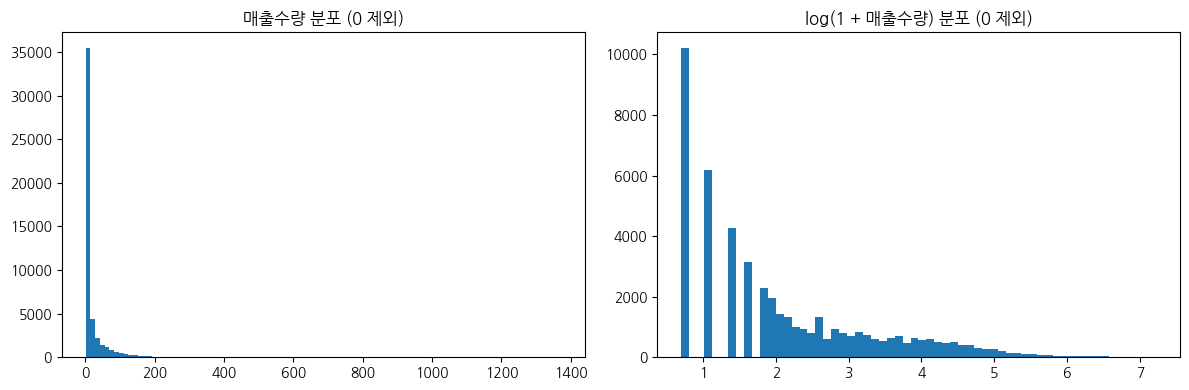

In [8]:
# 음수는 0으로 처리 (반품/취소로 추정되는 값)
train['매출수량'] = train['매출수량'].clip(lower=0)

# 값이 0보다 큰 경우만 분포 확인 (로그 스케일)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pos = train.loc[train['매출수량'] > 0, '매출수량']
ax[0].hist(pos, bins=100)
ax[0].set_title('매출수량 분포 (0 제외)')
ax[1].hist(np.log1p(pos), bins=60)
ax[1].set_title('log(1 + 매출수량) 분포 (0 제외)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_01_value_dist.png', dpi=120); plt.show()

> 📝 **관찰 포인트:** 오른쪽으로 꼬리가 긴(몇몇 날만 엄청 많이 팔리는) 분포라면,
> 모델 학습 시 `log1p(매출수량)`을 타깃으로 쓰는 것이 도움이 됩니다. (베이스라인 노트북에서 이렇게 합니다.)

## 4. 영업장별 매출 규모

,총 매출수량,비중(%)
영업장명,,
포레스트릿,305434,27.9
카페테리아,240930,22.0
화담숲주막,146311,13.4
담하,124917,11.4
미라시아,98077,9.0
느티나무 셀프BBQ,69805,6.4
화담숲카페,62634,5.7
연회장,28419,2.6
라그로타,17453,1.6


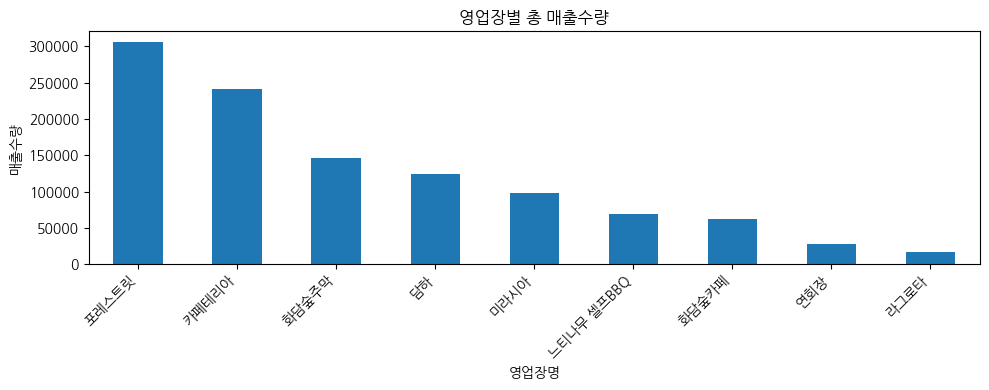

In [9]:
venue_sales = train.groupby('영업장명')['매출수량'].sum().sort_values(ascending=False)
venue_share = (venue_sales / venue_sales.sum() * 100).round(1)
display(pd.DataFrame({'총 매출수량': venue_sales, '비중(%)': venue_share}))

plt.figure(figsize=(10, 4))
venue_sales.plot(kind='bar')
plt.title('영업장별 총 매출수량'); plt.ylabel('매출수량'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_02_venue_sales.png', dpi=120); plt.show()

## 5. 시간에 따른 매출 흐름 (추세·계절성)
하루하루 값은 들쭉날쭉하므로 **7일 이동평균**(최근 7일 평균)을 같이 그리면 흐름이 잘 보입니다.

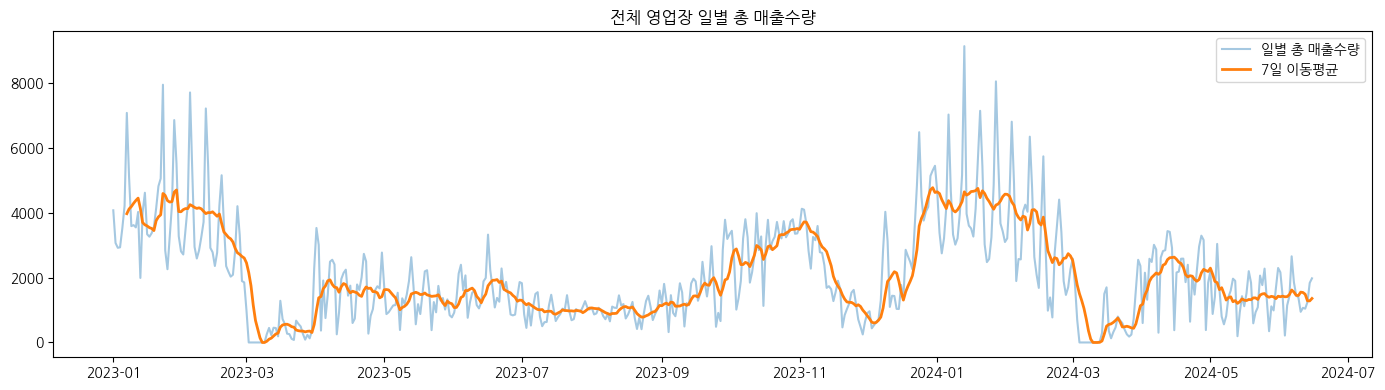

In [10]:
daily_total = train.groupby('영업일자')['매출수량'].sum()

plt.figure(figsize=(14, 4))
plt.plot(daily_total.index, daily_total.values, alpha=0.4, label='일별 총 매출수량')
plt.plot(daily_total.index, daily_total.rolling(7).mean(), linewidth=2, label='7일 이동평균')
plt.title('전체 영업장 일별 총 매출수량'); plt.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_03_daily_total.png', dpi=120); plt.show()

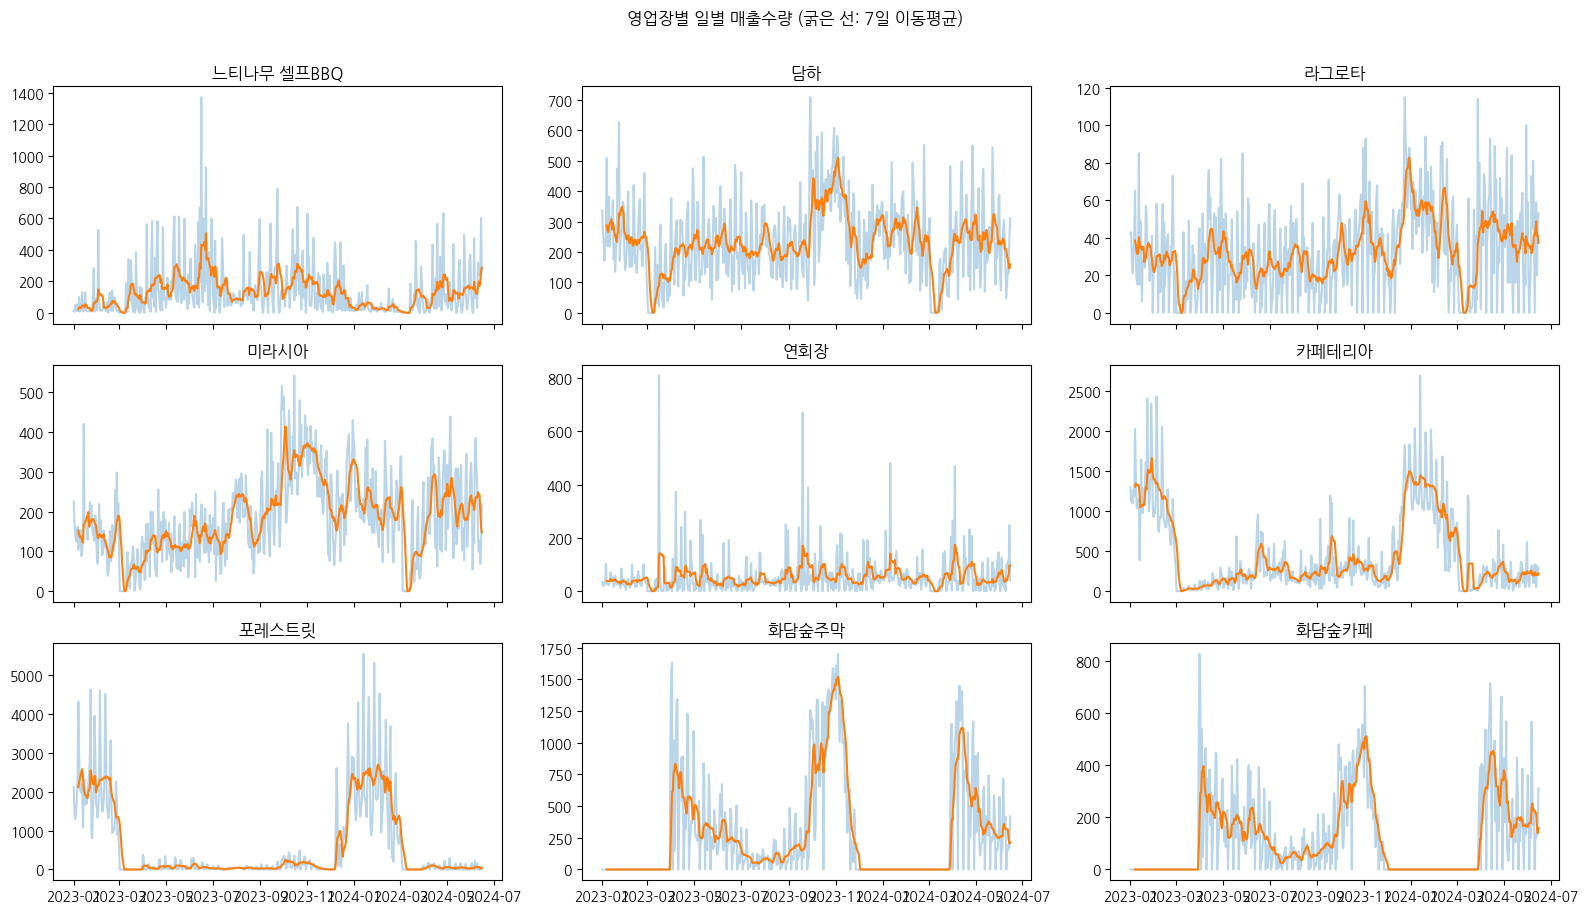

In [11]:
daily_venue = train.pivot_table(index='영업일자', columns='영업장명', values='매출수량', aggfunc='sum')
n = daily_venue.shape[1]
ncols = 3; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows), sharex=True)
for ax, v in zip(axes.flat, daily_venue.columns):
    ax.plot(daily_venue.index, daily_venue[v], alpha=0.3)
    ax.plot(daily_venue.index, daily_venue[v].rolling(7).mean(), linewidth=1.5)
    ax.set_title(v)
for ax in list(axes.flat)[n:]:
    ax.set_visible(False)
plt.suptitle('영업장별 일별 매출수량 (굵은 선: 7일 이동평균)', y=1.01)
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_04_daily_by_venue.png', dpi=120, bbox_inches='tight'); plt.show()

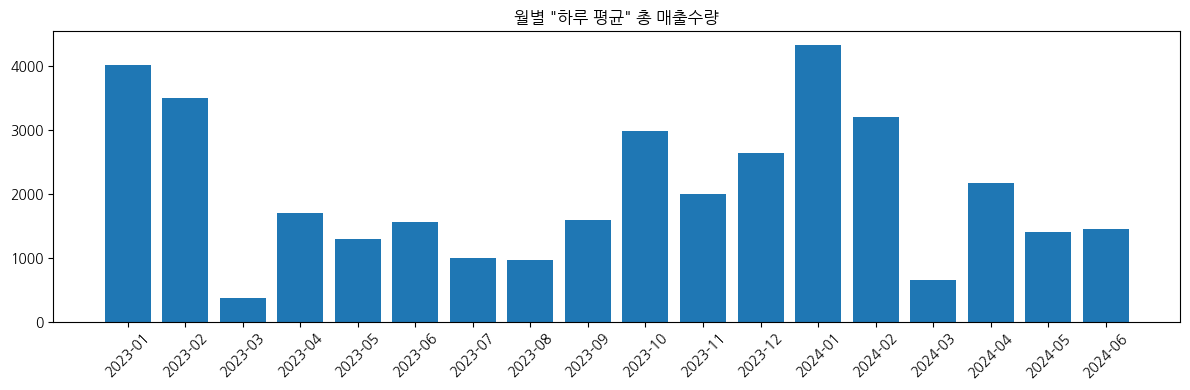

In [12]:
monthly = daily_total.resample('MS').mean()
plt.figure(figsize=(12, 4))
plt.bar([d.strftime('%Y-%m') for d in monthly.index], monthly.values)
plt.title('월별 "하루 평균" 총 매출수량')
plt.xticks(rotation=45)
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_05_monthly.png', dpi=120); plt.show()

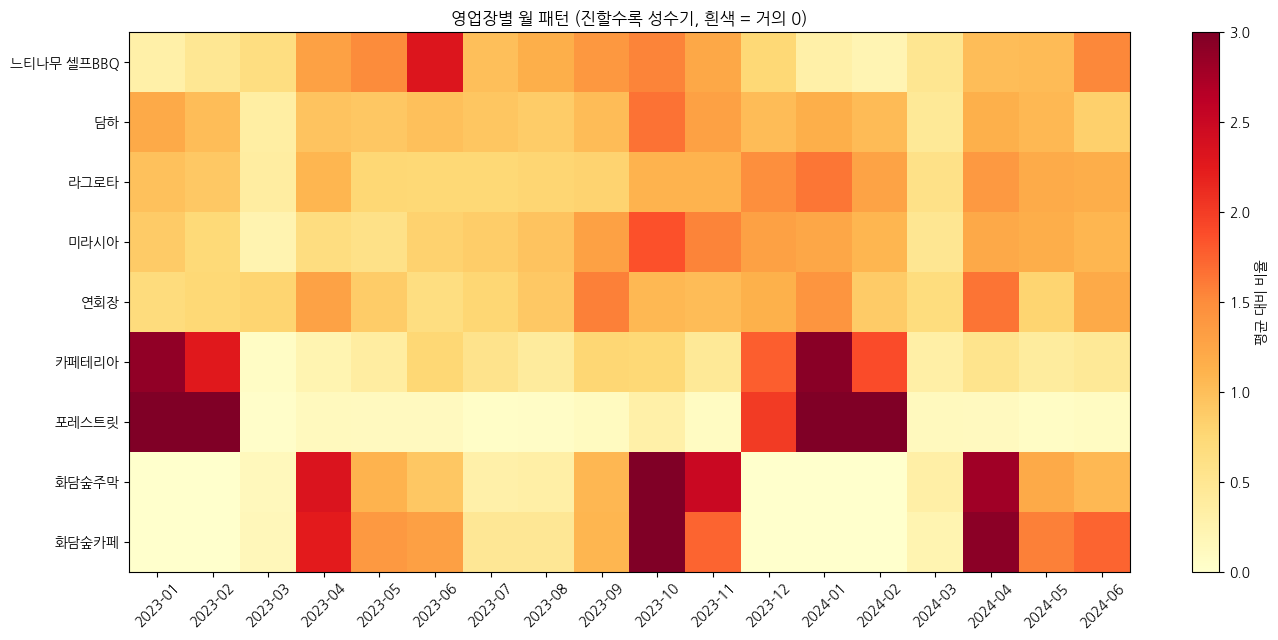

영업일자,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06
영업장명,,,,,,,,,,,,,,,,,,
느티나무 셀프BBQ,0.31,0.48,0.65,1.29,1.50,2.32,1.00,1.16,1.39,1.56,1.23,0.74,0.31,0.22,0.51,1.02,1.04,1.52
담하,1.21,1.02,0.35,0.95,0.92,0.99,0.94,0.87,1.03,1.66,1.30,1.03,1.15,1.04,0.45,1.14,1.06,0.84
라그로타,0.98,0.91,0.37,1.08,0.76,0.75,0.75,0.78,0.80,1.10,1.10,1.47,1.64,1.27,0.59,1.38,1.19,1.17
미라시아,0.88,0.73,0.24,0.66,0.59,0.81,0.86,0.96,1.30,1.85,1.55,1.30,1.24,1.08,0.50,1.21,1.17,1.09
연회장,0.68,0.74,0.79,1.29,0.87,0.66,0.77,0.91,1.58,1.06,1.03,1.14,1.41,0.89,0.68,1.64,0.79,1.20
카페테리아,2.89,2.27,0.07,0.23,0.37,0.75,0.56,0.41,0.77,0.74,0.45,1.77,2.93,1.89,0.33,0.54,0.39,0.45
포레스트릿,3.76,3.42,0.03,0.12,0.11,0.12,0.04,0.06,0.10,0.31,0.09,2.01,4.07,3.13,0.12,0.11,0.06,0.09
화담숲주막,0.00,0.00,0.13,2.33,1.11,0.92,0.30,0.32,1.07,3.95,2.50,0.00,0.00,0.00,0.32,2.79,1.21,1.06
화담숲카페,0.00,0.00,0.16,2.25,1.37,1.31,0.47,0.47,1.09,3.04,1.74,0.00,0.00,0.00,0.23,2.92,1.58,1.73


In [13]:
# 영업장별 월 패턴: (그 달의 하루 평균) / (그 영업장의 전체 하루 평균)
# 1보다 크면 성수기, 0에 가까우면 거의 안 팔리거나 휴장
vm = daily_venue.groupby(daily_venue.index.to_period('M')).mean()
season = (vm / daily_venue.mean()).T
plt.figure(figsize=(14, 0.5 * season.shape[0] + 2))
plt.imshow(season.values, aspect='auto', cmap='YlOrRd', vmin=0, vmax=3)
plt.colorbar(label='평균 대비 비율')
plt.xticks(range(season.shape[1]), [str(p) for p in season.columns], rotation=45)
plt.yticks(range(season.shape[0]), season.index)
plt.title('영업장별 월 패턴 (진할수록 성수기, 흰색 = 거의 0)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_05b_season_by_venue.png', dpi=120); plt.show()
display(season.round(2))

> 📝 **관찰 포인트:** 어느 달이 성수기/비수기인가? 2023년과 2024년의 같은 달을 비교하면 비슷한가?
> 영업장마다 성수기가 다른가? 어떤 영업장은 특정 달에 **아예 0(휴장)** 인가?
> → 이런 "시즌 시작·종료" 시점이 예측에서 가장 어려운 구간이 됩니다.

## 6. 요일 · 공휴일 효과
리조트는 **주말·공휴일**에 손님이 몰릴 것으로 예상됩니다. 실제로 그런지 확인합니다.

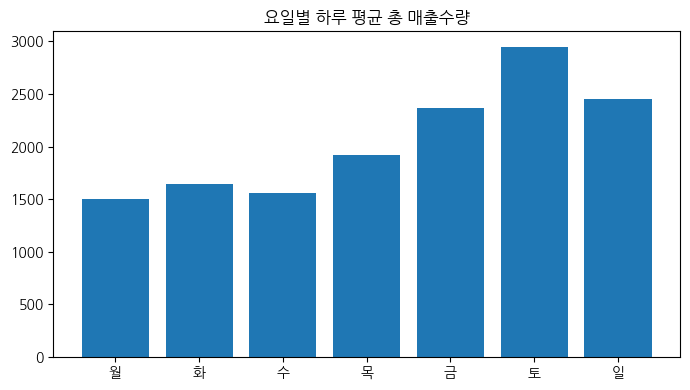

,mean,count
날짜유형,,
공휴일,3182.7,29
주말(토·일),2639.8,144
평일,1731.4,359


In [14]:
dow_name = ['월', '화', '수', '목', '금', '토', '일']
dt = daily_total.to_frame('총매출')
dt['요일'] = dt.index.dayofweek
dt['공휴일'] = dt.index.isin(KR_HOLIDAYS)

dow_mean = dt.groupby('요일')['총매출'].mean()
plt.figure(figsize=(7, 4))
plt.bar([dow_name[i] for i in dow_mean.index], dow_mean.values)
plt.title('요일별 하루 평균 총 매출수량')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_06_dow.png', dpi=120); plt.show()

def day_type(row):
    if row['공휴일']:
        return '공휴일'
    return '주말(토·일)' if row['요일'] >= 5 else '평일'
dt['날짜유형'] = dt.apply(day_type, axis=1)
display(dt.groupby('날짜유형')['총매출'].agg(['mean', 'count']).round(1))

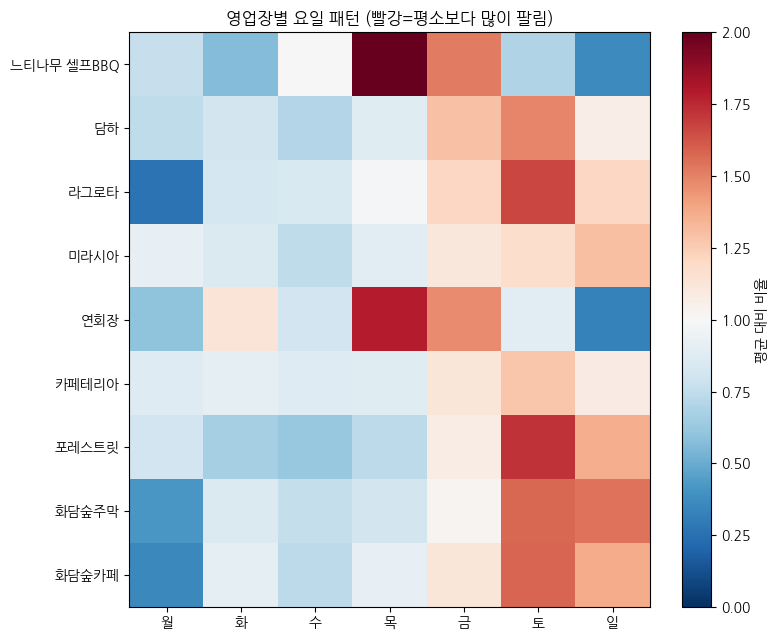

요일,0,1,2,3,4,5,6
영업장명,,,,,,,
느티나무 셀프BBQ,0.77,0.57,1.00,2.07,1.52,0.70,0.37
담하,0.74,0.82,0.71,0.88,1.29,1.49,1.07
라그로타,0.26,0.82,0.85,0.98,1.21,1.66,1.21
미라시아,0.92,0.86,0.75,0.89,1.11,1.17,1.30
연회장,0.60,1.13,0.81,1.79,1.47,0.89,0.32
카페테리아,0.87,0.90,0.87,0.88,1.12,1.27,1.08
포레스트릿,0.81,0.67,0.62,0.74,1.07,1.73,1.37
화담숲주막,0.42,0.85,0.76,0.82,1.03,1.57,1.54
화담숲카페,0.35,0.91,0.74,0.92,1.12,1.58,1.37


In [15]:
# 영업장별 요일 패턴: 각 영업장의 "전체 평균 대비 요일 평균의 비율"
# (1.0보다 크면 평소보다 많이 팔리는 요일)
dv = daily_venue.copy()
dv['요일'] = dv.index.dayofweek
dow_venue = dv.groupby('요일').mean()
dow_ratio = dow_venue / daily_venue.mean()

plt.figure(figsize=(8, 0.5 * dow_ratio.shape[1] + 2))
plt.imshow(dow_ratio.T.values, aspect='auto', cmap='RdBu_r', vmin=0, vmax=2)
plt.colorbar(label='평균 대비 비율')
plt.xticks(range(7), dow_name); plt.yticks(range(dow_ratio.shape[1]), dow_ratio.columns)
plt.title('영업장별 요일 패턴 (빨강=평소보다 많이 팔림)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_07_dow_by_venue.png', dpi=120); plt.show()
display(dow_ratio.T.round(2))

## 7. 메뉴 단위 분석
193개 메뉴가 모두 비슷하게 팔리지는 않을 것입니다. 특히 확인할 것:
- **많이 팔리는 메뉴 TOP 15**
- **0이 많은 메뉴** (가끔씩만 팔리는 메뉴 → 예측이 어렵고, 평가에서 실제값 0인 날은 제외됨)
- **단종/신규 메뉴** (기간 중간에 판매가 끝나거나 새로 시작된 메뉴)

In [16]:
menu_stats = train.groupby('영업장명_메뉴명').agg(
    총판매=('매출수량', 'sum'),
    일평균=('매출수량', 'mean'),
    판매일비율=('매출수량', lambda s: (s > 0).mean()),
)
first_sale = train[train['매출수량'] > 0].groupby('영업장명_메뉴명')['영업일자'].min()
last_sale = train[train['매출수량'] > 0].groupby('영업장명_메뉴명')['영업일자'].max()
menu_stats['첫판매일'] = first_sale
menu_stats['마지막판매일'] = last_sale
menu_stats = menu_stats.sort_values('총판매', ascending=False)

print('많이 팔린 메뉴 TOP 15')
display(menu_stats.head(15).round(2))

많이 팔린 메뉴 TOP 15


,총판매,일평균,판매일비율,첫판매일,마지막판매일
영업장명_메뉴명,,,,,
포레스트릿_꼬치어묵,68736,129.20,0.50,2023-01-01,2024-06-09
화담숲주막_해물파전,60126,113.02,0.54,2023-03-31,2024-06-15
포레스트릿_떡볶이,56427,106.07,0.60,2023-01-01,2024-06-15
포레스트릿_생수,41445,77.90,0.64,2023-01-01,2024-06-15
포레스트릿_치즈 핫도그,30404,57.15,0.60,2023-01-01,2024-06-15
카페테리아_수제 등심 돈까스,27336,51.38,0.95,2023-01-01,2024-06-15
카페테리아_단체식 18000(신),26651,50.10,0.36,2023-04-05,2024-06-14
화담숲카페_아메리카노 ICE,22525,42.34,0.53,2023-03-31,2024-06-15
포레스트릿_코카콜라,22039,41.43,0.59,2023-01-01,2024-06-15


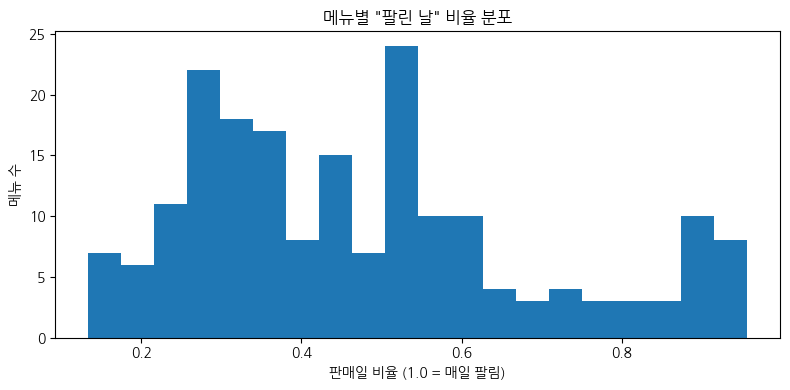

판매일 비율 10% 미만 메뉴 수: 0개
판매일 비율 30% 미만 메뉴 수: 48개
판매일 비율 50% 미만 메뉴 수: 109개


In [17]:
plt.figure(figsize=(8, 4))
plt.hist(menu_stats['판매일비율'], bins=20)
plt.xlabel('판매일 비율 (1.0 = 매일 팔림)'); plt.ylabel('메뉴 수')
plt.title('메뉴별 "팔린 날" 비율 분포')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_08_sale_day_ratio.png', dpi=120); plt.show()

for th in [0.1, 0.3, 0.5]:
    print(f'판매일 비율 {th:.0%} 미만 메뉴 수: {(menu_stats["판매일비율"] < th).sum()}개')

In [18]:
start, end = train['영업일자'].min(), train['영업일자'].max()
discontinued = menu_stats[menu_stats['마지막판매일'] < end - pd.Timedelta(days=30)]
new_menu = menu_stats[menu_stats['첫판매일'] > start + pd.Timedelta(days=30)]
never_sold = menu_stats[menu_stats['총판매'] == 0]

print(f'마지막 30일 동안 한 번도 안 팔린 메뉴(단종 의심): {len(discontinued)}개')
display(discontinued[['총판매', '첫판매일', '마지막판매일']].head(20))
print(f'시작 30일 이후에 처음 팔린 메뉴(신규 의심): {len(new_menu)}개')
display(new_menu[['총판매', '첫판매일', '마지막판매일']].head(20))
print(f'전 기간 한 번도 안 팔린 메뉴: {len(never_sold)}개')

menu_stats.to_csv(RESULT_DIR / 'eda_menu_stats.csv', encoding='utf-8-sig')

마지막 30일 동안 한 번도 안 팔린 메뉴(단종 의심): 13개


,총판매,첫판매일,마지막판매일
영업장명_메뉴명,,,
포레스트릿_복숭아 아이스티,15370,2023-01-01,2024-03-03
카페테리아_아메리카노(ICE),11386,2023-01-01,2024-03-03
카페테리아_아메리카노(HOT),11053,2023-01-01,2024-03-03
카페테리아_새우튀김 우동,9276,2023-01-01,2024-03-03
카페테리아_구슬아이스크림,8796,2023-01-01,2024-03-03
카페테리아_카페라떼(HOT),7376,2023-01-01,2024-03-03
카페테리아_복숭아 아이스티,6309,2023-01-01,2024-03-03
카페테리아_오픈푸드,5847,2023-01-01,2024-04-08
카페테리아_진사골 설렁탕,4769,2023-12-06,2024-03-03


시작 30일 이후에 처음 팔린 메뉴(신규 의심): 72개


,총판매,첫판매일,마지막판매일
영업장명_메뉴명,,,
화담숲주막_해물파전,60126,2023-03-31,2024-06-15
카페테리아_단체식 18000(신),26651,2023-04-05,2024-06-14
화담숲카페_아메리카노 ICE,22525,2023-03-31,2024-06-15
카페테리아_단체식 13000(신),20784,2023-04-18,2024-06-15
화담숲주막_병천순대,17339,2023-03-31,2024-06-15
화담숲주막_느린마을 막걸리,15187,2023-03-31,2024-06-15
화담숲주막_찹쌀식혜,13706,2023-03-31,2024-06-15
화담숲카페_메밀미숫가루,13563,2023-03-31,2024-06-15
화담숲주막_참살이 막걸리,12356,2023-03-31,2024-06-15


전 기간 한 번도 안 팔린 메뉴: 0개


## 8. 자기상관: "며칠 전 매출"이 오늘과 가장 비슷할까?
메뉴별로 **오늘 매출**과 **k일 전 매출**의 상관계수를 구하고, 193개 메뉴의 중앙값을 그립니다.
- 막대가 높을수록 "k일 전 값이 오늘 값을 잘 설명한다"는 뜻
- 만약 **7, 14, 21, 28일**에서 튀어 오른다면 → **"지난주 같은 요일" Lag 변수가 중요**하다는 근거가 됩니다.

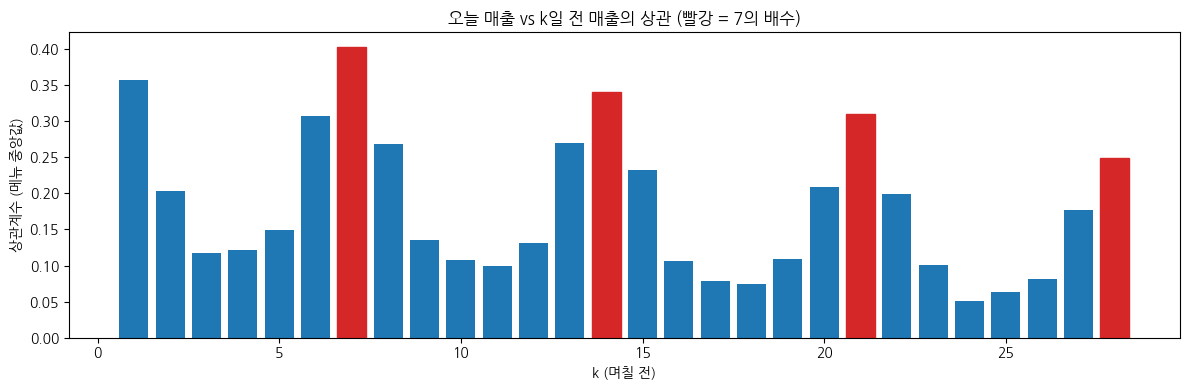

분석에 사용한 메뉴 수: 145


In [19]:
wide = train.pivot_table(index='영업일자', columns='영업장명_메뉴명', values='매출수량', aggfunc='sum').sort_index()
active = wide.loc[:, (wide > 0).mean() > 0.3]   # 너무 드물게 팔리는 메뉴는 제외
lags = range(1, 29)
acf_median = [active.apply(lambda s: s.corr(s.shift(k))).median() for k in lags]

plt.figure(figsize=(12, 4))
bars = plt.bar(list(lags), acf_median)
for k in [7, 14, 21, 28]:
    bars[k - 1].set_color('tab:red')
plt.xlabel('k (며칠 전)'); plt.ylabel('상관계수 (메뉴 중앙값)')
plt.title('오늘 매출 vs k일 전 매출의 상관 (빨강 = 7의 배수)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_09_autocorr.png', dpi=120); plt.show()
print('분석에 사용한 메뉴 수:', active.shape[1])

## 9. 초기 인사이트 정리 ✍️

| # | 질문 | 발견한 내용 | 모델에 어떻게 반영할까? |
|---|------|------------|------------------------|
| 1 | 데이터 품질 | 결측 0, 누락 날짜 0, 음수 14건(0.01%), 전체의 52.6%가 0 | 음수→0 처리, 평가에서 0은 제외되므로 "판매일 기준" 예측 |
| 2 | 영업장 규모 | 포레스트릿 27.9%, 카페테리아 22.0%가 절반 차지 / 라그로타 1.6% | 영업장을 범주형 변수로 사용 |
| 3 | 계절성 | 겨울(12~2월) 최고, 3월 초·중순 약 2주 전체 휴식, 봄(4월)·가을(10월) 봉우리. 포레스트릿은 1월에 평소의 3.8배, 화담숲은 12~2월 휴장 | 월·연중일자 변수, 영업장별 시즌 패턴 학습 |
| 4 | 요일/공휴일 | 평일 대비 주말 1.5배, 공휴일 1.8배 (공휴일이 겨울에 몰려 과대평가 가능성) | 요일·주말·공휴일 변수 |
| 5 | 영업장별 요일 패턴 | 대부분 토요일 최고, BBQ(목 2.07배)·연회장(목 1.79배)은 평일 단체 수요 | 영업장×요일 조합을 모델이 학습 |
| 6 | 메뉴 특성 | 판매일 50% 미만 메뉴 109개 / 단종 의심 13개는 대부분 겨울 시즌 종료(2024-03-03), 신규 의심 중 다수는 화담숲 재개장(2023-03-31) | 최근 판매 비율, 마지막 판매 후 경과일 변수 |
| 7 | 자기상관 | 7일 전(0.40) > 1일 전(0.36), 14·21·28일에도 봉우리 | 같은 요일 Lag(7/14/21/28) 변수 |